In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

%matplotlib inline

### 1. Dataset

In [2]:
dataset = pd.read_csv(r"C:\Users\dell\Desktop\ML_Algos\data\classification.csv")
dataset

,x1,x2,label
0,0.448196,0.130705,0.0
1,0.773273,0.086142,0.0
2,0.418814,0.634072,1.0
3,0.951985,0.403000,0.0
4,0.628209,0.040618,0.0
...,...,...,...
195,0.213643,0.266799,1.0
196,0.853088,0.248827,0.0
197,0.818051,0.490837,0.0
198,0.761045,0.977934,1.0


In [3]:
X = dataset[['x1', 'x2']].values
y = dataset[['label']].values

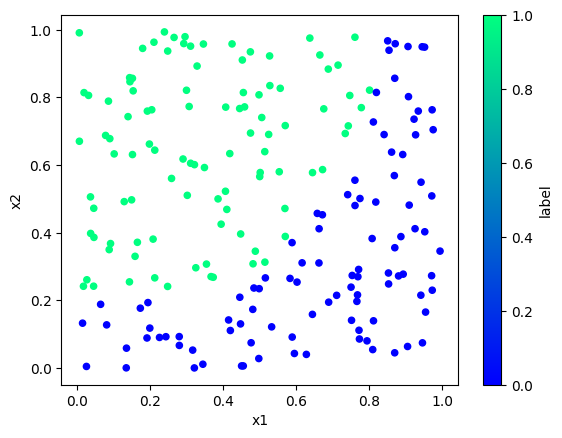

In [4]:
dataset.plot.scatter(x='x1',y='x2', c='label', colormap='winter')
plt.show()

In [5]:
X_train, X_test, y_train, y_test =  train_test_split(X, y, test_size=0.2, random_state=42)

print('x_train shape  : ', X_train.shape)
print('x_test shape  : ', X_test.shape)
print('y_train shape  : ', y_train.shape)
print('y_test shape  : ', y_test.shape)

x_train shape  :  (160, 2)
x_test shape  :  (40, 2)
y_train shape  :  (160, 1)
y_test shape  :  (40, 1)


### 2. Modèle


In [6]:
# La fonction sigmoide
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [7]:
def initialisation(X):
    W = np.random.randn(X.shape[1], 1)
    b = np.random.randn(1)
    return (W, b)

In [8]:
# Modèle
def modele(X, W, b):
    Z = X.dot(W) + b
    A = sigmoid(Z)
    return A

W,b=initialisation(X)
modele(X, W, b)

### 3. Fonction Coût 

In [9]:
def log_loss(y, A):
    return 1/len(y) * np.sum(-y * np.log(A) - (1 - y) * np.log(1 - A))

### 4. Optimisation - Gradient et Descente de Gradient

In [10]:
def gradients(X, A, y):
    dW = 1/len(y) * np.dot(X.T, A - y)
    db = 1/len(y) * np.sum(A - y)
    return (dW, db)

In [11]:
def optimisation(X, W, b, A, y, learning_rate):
    dW, db = gradients(X, A, y)
    W = W - learning_rate * dW
    b = b - learning_rate * db
    return (W, b)

### 5. Prédiction

In [12]:
def predict(X, W, b):
    A = modele(X, W, b)
    print(A)
    return A >= 0.5

### 5. Modèle final

In [13]:
def regression_logistique(X, y, learning_rate=0.1, n_iter=10000):
  # Initialisation
    W, b = initialisation(X)
    loss_history = []
  # Entrainement
    for i in range(n_iter):
        A = modele(X, W, b)
        loss_history.append(log_loss(y, A))
        W, b = optimisation(X, W, b, A, y, learning_rate=0.1)

  # Prediction
    plt.plot(loss_history)
    plt.xlabel('n_iteration')
    plt.ylabel('Log_loss')
    plt.title('Evolution des erreurs')
    return W,b

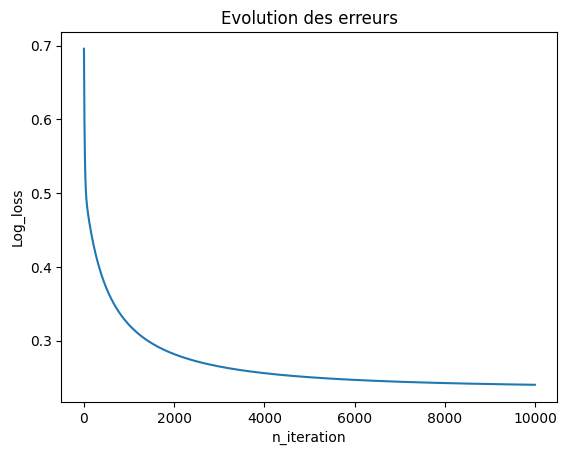

In [14]:
W,b=regression_logistique(X_train, y_train)

### 5. 1 Evaluation du modèle et Visualisation


In [15]:
from sklearn.metrics import accuracy_score
y_pred = predict(X_test, W, b)
print("Accuracy=",accuracy_score(y_test, y_pred))

[[9.99326556e-01]
 [6.05218847e-01]
 [6.97815207e-02]
 [8.33424563e-01]
 [9.96306270e-01]
 [9.77077036e-01]
 [9.87310839e-01]
 [1.22862428e-02]
 [3.06835795e-01]
 [4.89911428e-01]
 [7.01777069e-01]
 [1.24067705e-03]
 [8.65720224e-02]
 [6.51313270e-02]
 [3.64063784e-01]
 [4.07877512e-03]
 [6.46427112e-01]
 [4.98406039e-02]
 [9.98688816e-01]
 [2.29889242e-01]
 [9.97422013e-01]
 [9.89119611e-01]
 [5.12058523e-04]
 [1.88186276e-01]
 [5.10490539e-01]
 [9.32518524e-01]
 [9.44211542e-01]
 [1.46536388e-02]
 [7.34205070e-02]
 [9.98939247e-01]
 [3.46912603e-01]
 [9.29322129e-01]
 [7.00876895e-01]
 [6.89651375e-02]
 [9.73313154e-01]
 [9.98973575e-01]
 [1.05248716e-01]
 [9.98523876e-01]
 [2.49487342e-03]
 [9.99402779e-01]]
Accuracy= 0.85


[0.60474088]
[ True]
[0.00193541]
[False]
[0.31755516]
[False]


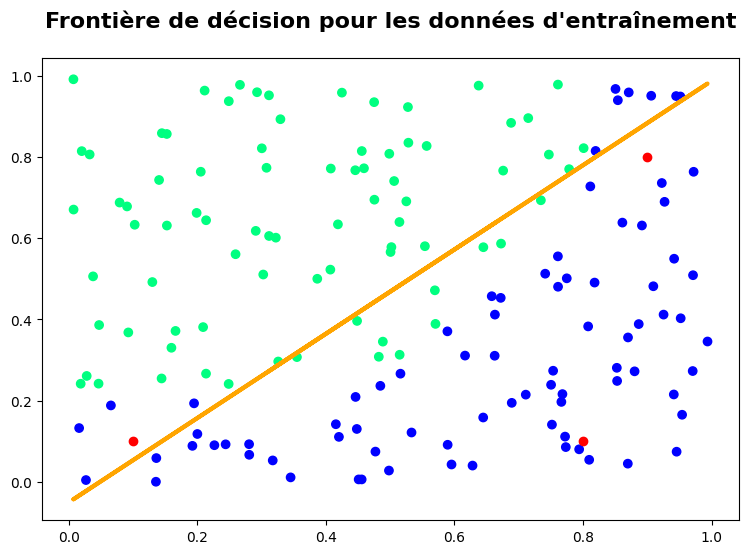

In [16]:
# Visualiser le dataset des données d'entraînement
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X_train[:,0], X_train[:, 1], c=y_train, cmap='winter')

# Dessiner la frontière de décision
#x1 = np.linspace(0, 1, 200)
x1 = X_train[:,0]
x2 = ( - W[0] * X_train[:,0] - b) / W[1]
ax.plot(x1, x2, c='orange', lw=3)

ax.set_title("Frontière de décision pour les données d'entraînement\n", fontsize=16, fontweight="bold")
# Prédire la classe de nouveaux éléments

new_1=np.array([0.1,0.1])
new_2=np.array([0.8,0.1])
new_3=np.array([0.9,0.8])
ax.scatter(new_1[0], new_1[1], c='r')
ax.scatter(new_2[0], new_2[1], c='r')
ax.scatter(new_3[0], new_3[1], c='r')
print(predict(new_1, W, b))
print(predict(new_2, W, b))
print(predict(new_3, W, b))

plt.show()

[0.60474088]
[ True]
[0.00193541]
[False]
[0.31755516]
[False]


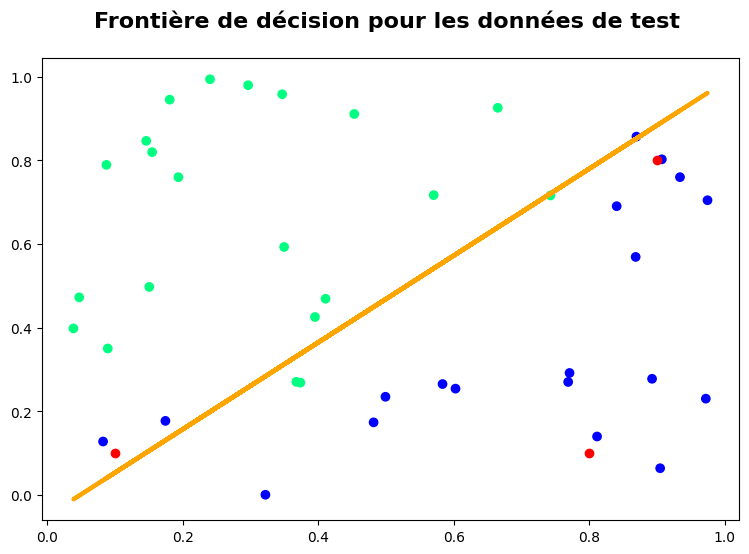

In [17]:
# Visualiser le dataset des données d'entraînement
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X_test[:,0], X_test[:, 1], c=y_test, cmap='winter')

# Dessiner la frontière de décision
#x1 = np.linspace(0, 1, 200)
x1 = X_test[:,0]
x2 = ( - W[0] * X_test[:,0] - b) / W[1]
ax.plot(x1, x2, c='orange', lw=3)
ax.set_title("Frontière de décision pour les données de test \n", fontsize=16, fontweight="bold")
# Prédire la classe de nouveaux éléments

new_1=np.array([0.1,0.1])
new_2=np.array([0.8,0.1])
new_3=np.array([0.9,0.8])
ax.scatter(new_1[0], new_1[1], c='r')
ax.scatter(new_2[0], new_2[1], c='r')
ax.scatter(new_3[0], new_3[1], c='r')
print(predict(new_1, W, b))
print(predict(new_2, W, b))
print(predict(new_3, W, b))

plt.show()

In [18]:
#Affichage de la matrice de confusion des données d'entrainement

from sklearn.metrics import confusion_matrix
y_train_pred = predict(X_train, W, b)
cm = confusion_matrix(y_train, y_train_pred)
print(cm)

[[9.98043519e-01]
 [5.59621283e-02]
 [9.09906005e-01]
 [8.67232024e-01]
 [4.06695031e-01]
 [7.05840384e-01]
 [9.56770152e-01]
 [9.98569661e-01]
 [1.10762438e-02]
 [1.43215188e-01]
 [8.07867084e-01]
 [1.02272435e-02]
 [5.76029341e-01]
 [3.83719872e-04]
 [1.86983245e-03]
 [1.72066346e-01]
 [3.64072620e-01]
 [9.59966875e-01]
 [8.21352858e-01]
 [1.00369951e-01]
 [6.03419643e-04]
 [1.18353709e-01]
 [9.58418152e-01]
 [1.15355467e-01]
 [9.90367314e-01]
 [5.27495241e-01]
 [1.48519049e-01]
 [7.75982525e-01]
 [1.97606957e-01]
 [6.25304416e-01]
 [9.98968400e-01]
 [9.40076149e-01]
 [1.47085218e-02]
 [9.58105502e-01]
 [9.99924876e-01]
 [9.74980312e-01]
 [9.91413472e-01]
 [7.42893454e-01]
 [8.06131557e-01]
 [9.87166794e-01]
 [9.08505213e-01]
 [5.19860478e-01]
 [2.64613670e-01]
 [1.75052718e-02]
 [7.20083797e-02]
 [4.38350602e-03]
 [9.54907982e-01]
 [9.65987284e-01]
 [9.97060275e-01]
 [4.74766196e-02]
 [9.99477036e-01]
 [1.20788744e-01]
 [5.45653904e-01]
 [4.26234490e-01]
 [1.60132207e-02]
 [1.190832

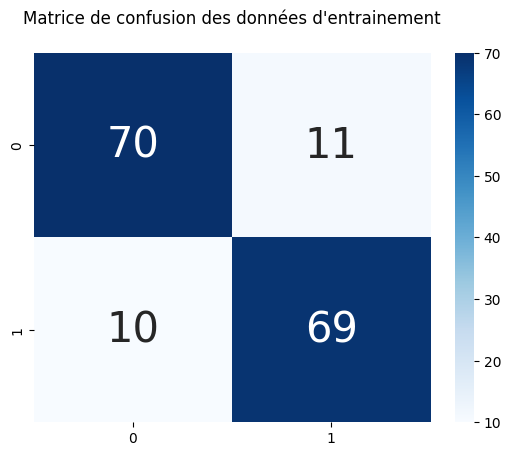

In [19]:
# Plot confusion matrix
import seaborn as sns
import pandas as pd
# confusion matrix sns heatmap 
## https://www.kaggle.com/agungor2/various-confusion-matrix-plots
ax = plt.axes()
df_cm = cm
sns.heatmap(df_cm, annot=True, annot_kws={"size": 30}, fmt='d',cmap="Blues", ax = ax )
ax.set_title('Matrice de confusion des données d\'entrainement\n')
plt.show()

In [20]:
#Affichage de la matrice de confusion des données de test

from sklearn.metrics import confusion_matrix
y_test_pred = predict(X_test, W, b)
cm = confusion_matrix(y_test, y_test_pred)
print(cm)

[[9.99326556e-01]
 [6.05218847e-01]
 [6.97815207e-02]
 [8.33424563e-01]
 [9.96306270e-01]
 [9.77077036e-01]
 [9.87310839e-01]
 [1.22862428e-02]
 [3.06835795e-01]
 [4.89911428e-01]
 [7.01777069e-01]
 [1.24067705e-03]
 [8.65720224e-02]
 [6.51313270e-02]
 [3.64063784e-01]
 [4.07877512e-03]
 [6.46427112e-01]
 [4.98406039e-02]
 [9.98688816e-01]
 [2.29889242e-01]
 [9.97422013e-01]
 [9.89119611e-01]
 [5.12058523e-04]
 [1.88186276e-01]
 [5.10490539e-01]
 [9.32518524e-01]
 [9.44211542e-01]
 [1.46536388e-02]
 [7.34205070e-02]
 [9.98939247e-01]
 [3.46912603e-01]
 [9.29322129e-01]
 [7.00876895e-01]
 [6.89651375e-02]
 [9.73313154e-01]
 [9.98973575e-01]
 [1.05248716e-01]
 [9.98523876e-01]
 [2.49487342e-03]
 [9.99402779e-01]]
[[16  3]
 [ 3 18]]


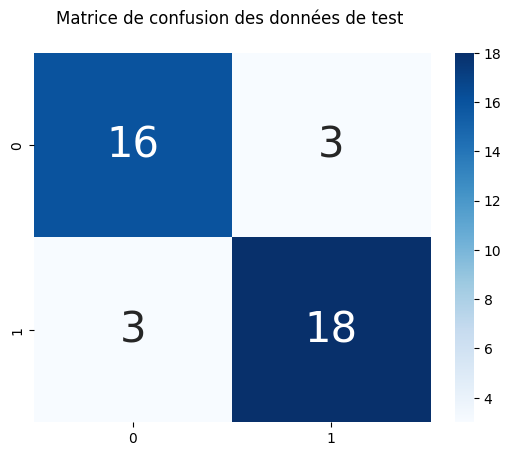

In [21]:
# confusion matrix sns heatmap 
## https://www.kaggle.com/agungor2/various-confusion-matrix-plots
ax = plt.axes()
df_cm = cm
sns.heatmap(df_cm, annot=True, annot_kws={"size": 30}, fmt='d',cmap="Blues", ax = ax )
ax.set_title('Matrice de confusion des données de test \n')
plt.show()